<a href="https://colab.research.google.com/github/galang264/Data-Science/blob/main/TUGAS_WEEK_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **EKSPLORASI DATA PERTANDINGAN PIALA DUNIA 2022**
---


1. Import Library


In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 100)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'axes.axisbelow': True, 'axes.titleweight': 'bold'})
B, O, G, R, GR = '#1f5fa8', '#e07b22', '#6b7280', '#c0392b', '#2e8b57'

2. Load data


In [2]:
import os
FILE = 'Tugas_Data_Science.xlsx'
if not os.path.exists(FILE):
    try:
        from google.colab import files
        up = files.upload()              # pilih file .xlsx
        FILE = list(up.keys())[0]
    except ImportError:
        raise FileNotFoundError('Letakkan Tugas_Data_Science.xlsx di folder yang sama.')

df = pd.read_excel(FILE, sheet_name='Fifa_world_cup_matches')
print(df.shape)
df.head()

Saving Tugas Data Science.xlsx to Tugas Data Science.xlsx
(64, 88)


,team1,team2,possession team1,possession team2,possession in contest,number of goals team1,number of goals team2,date,hour,category,total attempts team1,total attempts team2,conceded team1,conceded team2,goal inside the penalty area team1,goal inside the penalty area team2,goal outside the penalty area team1,goal outside the penalty area team2,assists team1,assists team2,on target attempts team1,on target attempts team2,off target attempts team1,off target attempts team2,attempts inside the penalty area team1,attempts inside the penalty area team2,attempts outside the penalty area team1,attempts outside the penalty area team2,left channel team1,left channel team2,left inside channel team1,left inside channel team2,central channel team1,central channel team2,right inside channel team1,right inside channel team2,right channel team1,right channel team2,total offers to receive team1,total offers to receive team2,inbehind offers to receive team1,inbehind offers to receive team2,inbetween offers to receive team1,inbetween offers to receive team2,infront offers to receive team1,infront offers to receive team2,receptions between midfield and defensive lines team1,receptions between midfield and defensive lines team2,attempted line breaks team1,attempted line breaks team2,completed line breaksteam1,completed line breaks team2,attempted defensive line breaks team1,attempted defensive line breaks team2,completed defensive line breaksteam1,completed defensive line breaks team2,yellow cards team1,yellow cards team2,red cards team1,red cards team2,fouls against team1,fouls against team2,offsides team1,offsides team2,passes team1,passes team2,passes completed team1,passes completed team2,crosses team1,crosses team2,crosses completed team1,crosses completed team2,switches of play completed team1,switches of play completed team2,corners team1,corners team2,free kicks team1,free kicks team2,penalties scored team1,penalties scored team2,goal preventions team1,goal preventions team2,own goals team1,own goals team2,forced turnovers team1,forced turnovers team2,defensive pressures applied team1,defensive pressures applied team2
0,QATAR,ECUADOR,0.42,0.50,0.08,0,2,2022-11-20,17:00:00,Group A,5,6,2,0,0,2,0,0,0,1,0,3,5,3,2,4,3,2,15,8,0,7,3,6,1,4,9,6,520,532,116,127,235,187,169,218,5,8,136,155,86,99,9,13,4,7,4,2,0,0,15,15,3,4,450,480,381,409,9,14,4,4,9,9,1,3,19,17,0,1,6,5,0,0,52,72,256,279
1,ENGLAND,IRAN,0.72,0.19,0.09,6,2,2022-11-21,14:00:00,Group B,13,8,2,6,6,2,0,0,6,1,7,3,3,4,10,6,3,2,11,3,5,0,2,3,3,1,11,0,1061,212,207,53,386,86,468,73,16,4,238,101,178,45,25,7,16,4,0,2,0,0,9,14,2,2,809,224,730,154,23,8,7,1,12,3,8,0,16,10,0,1,8,13,0,0,63,72,139,416
2,SENEGAL,NETHERLANDS,0.44,0.45,0.11,0,2,2022-11-21,17:00:00,Group A,14,9,2,0,0,2,0,0,0,1,3,3,8,5,7,5,7,4,12,11,4,2,2,2,4,7,13,20,502,506,123,117,230,191,149,198,15,14,151,162,89,96,22,22,15,10,2,1,0,0,13,13,2,1,383,438,313,374,19,25,7,8,9,6,6,7,14,14,0,0,9,15,0,0,63,73,263,251
3,UNITED STATES,WALES,0.51,0.39,0.10,1,1,2022-11-21,20:00:00,Group B,6,7,1,1,1,1,0,0,1,0,1,3,4,3,4,5,2,2,14,7,5,2,4,5,4,2,11,7,725,436,149,100,336,172,240,164,12,9,199,174,146,103,23,17,15,8,4,2,0,0,15,10,1,1,569,409,509,321,31,15,4,6,5,8,5,3,11,15,0,1,7,7,0,0,81,72,242,292
4,ARGENTINA,SAUDI ARABIA,0.64,0.24,0.12,1,2,2022-11-22,11:00:00,Group C,14,3,2,1,1,2,0,0,0,1,6,2,5,0,10,3,4,0,12,3,4,2,5,3,8,3,18,8,650,268,157,69,177,131,316,68,26,9,191,137,127,68,39,15,25,7,0,6,0,0,7,21,10,1,610,267,529,190,29,9,12,2,5,7,9,2,22,16,1,0,4,14,0,0,65,80,163,361


3. Pembersihan & profil data

In [3]:
# Rapikan nama kolom (spasi ganda, "line breaksteam1" tanpa spasi)
df.columns = [c.strip().replace('  ', ' ') for c in df.columns]
df = df.rename(columns={'completed line breaksteam1': 'completed line breaks team1',
                        'completed defensive line breaksteam1': 'completed defensive line breaks team1'})

print('Baris, kolom      :', df.shape)
print('Total nilai kosong:', df.isna().sum().sum())
print('Baris duplikat    :', df.duplicated().sum())
print('Rentang tanggal   :', df['date'].min().date(), 's/d', df['date'].max().date())
print(df['category'].value_counts())
df.dtypes.value_counts()

Baris, kolom      : (64, 88)
Total nilai kosong: 0
Baris duplikat    : 0
Rentang tanggal   : 2022-11-20 s/d 2022-12-18
category
Round of 16                 8
Group B                     6
Group C                     6
Group D                     6
Group A                     6
Group F                     6
Group E                     6
Group G                     6
Group H                     6
Quarter-final               4
Semi-final                  2
Play-off for third place    1
Final                       1
Name: count, dtype: int64


,count
int64,80
object,4
float64,3
datetime64[ns],1


In [4]:
# Cek konsistensi
poss_sum = df['possession team1'] + df['possession team2'] + df['possession in contest']
print('Possession total (min-max):', round(poss_sum.min(), 3), '-', round(poss_sum.max(), 3))
for t in ['team1', 'team2']:
    print(t, '| operan sukses > operan:', (df[f'passes completed {t}'] > df[f'passes {t}']).sum(),
          '| tembakan on+off > total:', ((df[f'on target attempts {t}'] + df[f'off target attempts {t}']) > df[f'total attempts {t}']).sum())

Possession total (min-max): 1.0 - 1.01
team1 | operan sukses > operan: 0 | tembakan on+off > total: 0
team2 | operan sukses > operan: 0 | tembakan on+off > total: 0


4. Feature engineering

In [5]:
# Level pertandingan
df['goals'] = df['number of goals team1'] + df['number of goals team2']
df['stage'] = np.where(df['category'].str.startswith('Group'), 'Grup', 'Gugur')
df['cards'] = df['yellow cards team1'] + df['yellow cards team2']
df['fouls_total'] = df['fouls against team1'] + df['fouls against team2']

# Level tim-pertandingan: tiap laga menjadi 2 baris (sudut pandang tiap tim)
rows = []
for i, r in df.iterrows():
    for a, b in (('team1', 'team2'), ('team2', 'team1')):
        rows.append(dict(match=i, team=r[a], stage=r['stage'],
            gf=r[f'number of goals {a}'], ga=r[f'number of goals {b}'],
            poss=r[f'possession {a}'], att=r[f'total attempts {a}'], ont=r[f'on target attempts {a}'],
            passes=r[f'passes {a}'], pc=r[f'passes completed {a}'], yc=r[f'yellow cards {a}'],
            fouls=r[f'fouls against {a}'], corners=r[f'corners {a}'],
            press=r[f'defensive pressures applied {a}'], lb=r[f'completed line breaks {a}']))
L = pd.DataFrame(rows)
L['pacc'] = L['pc'] / L['passes']                       # akurasi operan
L['res'] = np.sign(L['gf'] - L['ga'])                   # 1 menang, 0 seri, -1 kalah
L['hasil'] = L['res'].map({1: 'Menang', 0: 'Seri', -1: 'Kalah'})
print(L.shape)
L.head()

(128, 18)


,match,team,stage,gf,ga,poss,att,ont,passes,pc,yc,fouls,corners,press,lb,pacc,res,hasil
0,0,QATAR,Grup,0,2,0.42,5,0,450,381,4,15,1,256,86,0.846667,-1,Kalah
1,0,ECUADOR,Grup,2,0,0.50,6,3,480,409,2,15,3,279,99,0.852083,1,Menang
2,1,ENGLAND,Grup,6,2,0.72,13,7,809,730,0,9,8,139,178,0.902349,1,Menang
3,1,IRAN,Grup,2,6,0.19,8,3,224,154,2,14,0,416,45,0.687500,-1,Kalah
4,2,SENEGAL,Grup,0,2,0.44,14,3,383,313,2,13,6,263,89,0.817232,-1,Kalah


A. Analisis Univariate

A1. Total gol per pertandingan

count    64.00
mean      2.69
std       1.89
min       0.00
25%       1.00
50%       2.00
75%       3.25
max       8.00
Name: goals, dtype: float64
Median: 2.0 | Skewness: 0.76
Shapiro-Wilk p = 0.0008 (p < 0.05 -> tidak normal)
Laga >= 6 gol:
     team1       team2  goals
   ENGLAND        IRAN      8
     SPAIN  COSTA RICA      7
  CAMEROON      SERBIA      6
COSTA RICA     GERMANY      6
  PORTUGAL SWITZERLAND      7
 ARGENTINA      FRANCE      6


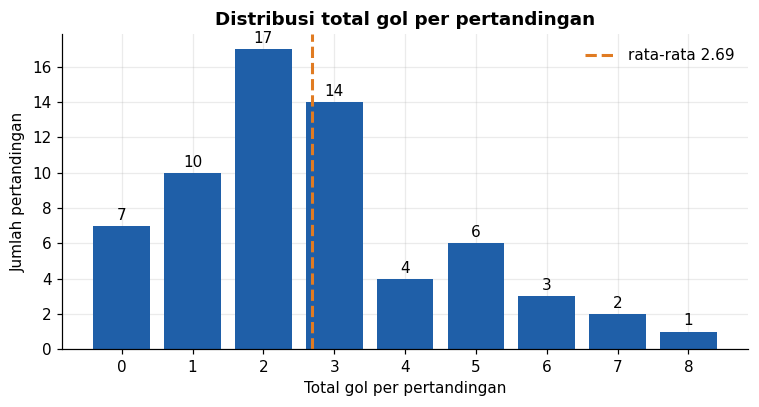

In [6]:
print(df['goals'].describe().round(2))
print('Median:', df['goals'].median(), '| Skewness:', round(df['goals'].skew(), 2))
print('Shapiro-Wilk p =', round(stats.shapiro(df['goals'])[1], 4), '(p < 0.05 -> tidak normal)')
print('Laga >= 6 gol:'); print(df.loc[df.goals >= 6, ['team1', 'team2', 'goals']].to_string(index=False))

vc = df['goals'].value_counts().sort_index().reindex(range(df.goals.max() + 1), fill_value=0)
fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(vc.index, vc.values, color=B); ax.bar_label(bars, padding=2)
ax.axvline(df.goals.mean(), color=O, ls='--', lw=2, label=f'rata-rata {df.goals.mean():.2f}')
ax.set(xlabel='Total gol per pertandingan', ylabel='Jumlah pertandingan', title='Distribusi total gol per pertandingan')
ax.set_xticks(vc.index); ax.legend(frameon=False); plt.tight_layout(); plt.show()

A2. Penguasaan bola, tembakan, operan, pelanggaran (per tim)

,count,mean,std,min,25%,50%,75%,max,median,skew
Penguasaan bola,128.0,0.44,0.12,0.14,0.35,0.45,0.53,0.78,0.45,0.08
Total tembakan,128.0,11.21,5.39,0.00,8.00,10.00,14.00,32.00,10.00,0.99
Operan,128.0,500.81,160.96,224.00,392.25,492.50,585.75,1070.00,492.50,0.99
Akurasi operan,128.0,0.84,0.06,0.65,0.81,0.85,0.88,0.95,0.85,-1.05
Pelanggaran,128.0,12.50,4.56,3.00,9.00,12.00,15.00,30.00,12.00,0.82
Kartu kuning,128.0,1.77,1.62,0.00,1.00,2.00,2.00,8.00,2.00,1.46


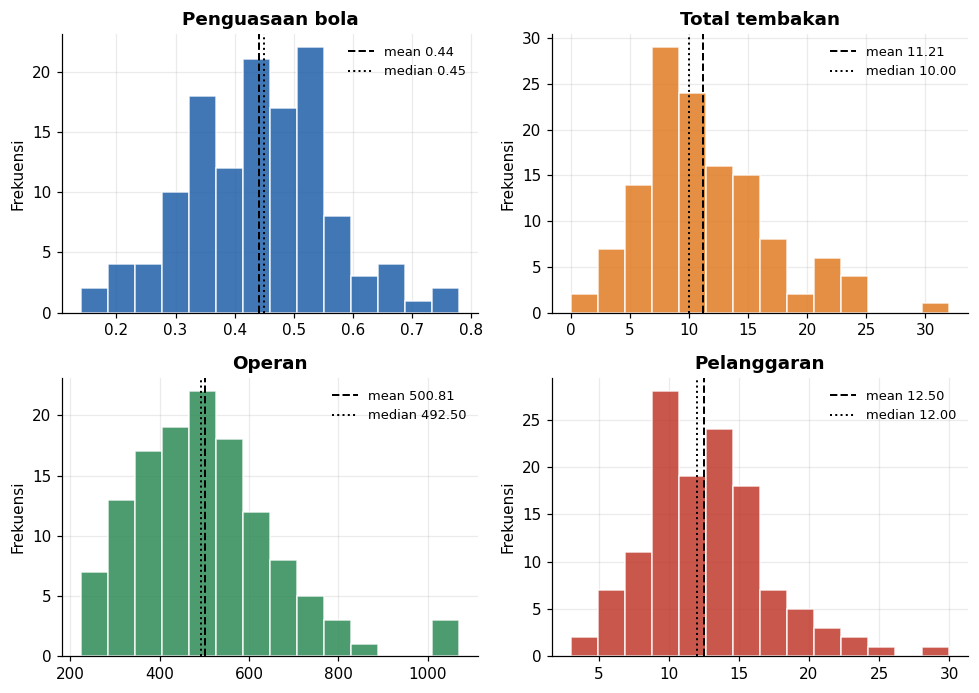

In [7]:
cols = {'poss': 'Penguasaan bola', 'att': 'Total tembakan', 'passes': 'Operan', 'pacc': 'Akurasi operan',
        'fouls': 'Pelanggaran', 'yc': 'Kartu kuning'}
desc = L[list(cols)].describe().T
desc['median'] = L[list(cols)].median(); desc['skew'] = L[list(cols)].skew()
display(desc.rename(index=cols).round(2))

fig, axs = plt.subplots(2, 2, figsize=(9, 6.4))
for ax, (c, col) in zip(axs.flat, [('poss', B), ('att', O), ('passes', GR), ('fouls', R)]):
    ax.hist(L[c], bins=14, color=col, alpha=.85, edgecolor='white')
    ax.axvline(L[c].mean(), color='k', ls='--', lw=1.3, label=f'mean {L[c].mean():.2f}')
    ax.axvline(L[c].median(), color='k', ls=':', lw=1.3, label=f'median {L[c].median():.2f}')
    ax.set(title=cols[c], ylabel='Frekuensi'); ax.legend(fontsize=8.5, frameon=False)
plt.tight_layout(); plt.show()

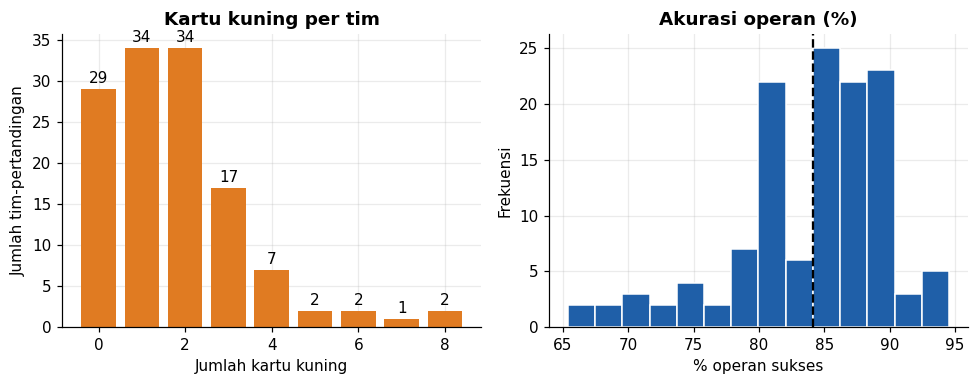

Shapiro possession p = 0.594


In [8]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.6))
yc = L['yc'].value_counts().sort_index()
b = axs[0].bar(yc.index, yc.values, color=O); axs[0].bar_label(b, padding=2)
axs[0].set(title='Kartu kuning per tim', xlabel='Jumlah kartu kuning', ylabel='Jumlah tim-pertandingan')
axs[1].hist(L['pacc'] * 100, bins=14, color=B, edgecolor='white'); axs[1].axvline(L['pacc'].mean() * 100, color='k', ls='--')
axs[1].set(title='Akurasi operan (%)', xlabel='% operan sukses', ylabel='Frekuensi')
plt.tight_layout(); plt.show()
print('Shapiro possession p =', round(stats.shapiro(L['poss'])[1], 3))

B. Analisis Bivariate

B1. Hubungan statistik tim dengan gol dicetak

,Variabel,Pearson r,Spearman rho,p (Spearman)
0,Tembakan on target,0.582,0.568,0.000
1,Total tembakan,0.347,0.311,0.000
2,Line break berhasil,0.258,0.116,0.192
3,Penguasaan bola,0.130,-0.005,0.952
4,Operan,0.174,0.034,0.706
5,Akurasi operan,0.123,0.054,0.548
6,Corner,0.132,0.092,0.300


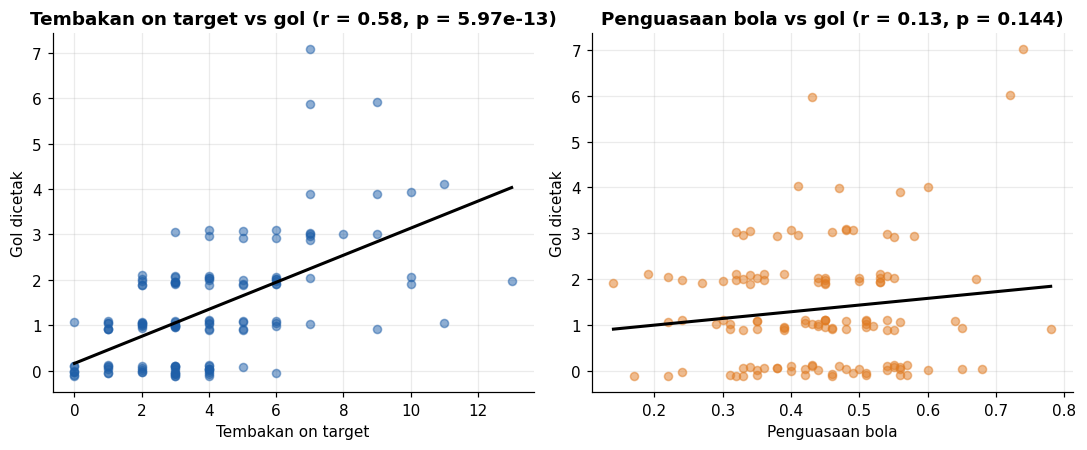

Regresi: gol = 0.16 + 0.30 x on_target  (R2 = 0.34)


In [9]:
res = []
for c, name in [('ont', 'Tembakan on target'), ('att', 'Total tembakan'), ('lb', 'Line break berhasil'),
                ('poss', 'Penguasaan bola'), ('passes', 'Operan'), ('pacc', 'Akurasi operan'), ('corners', 'Corner')]:
    r, p = stats.pearsonr(L[c], L['gf']); rs, ps = stats.spearmanr(L[c], L['gf'])
    res.append([name, r, rs, ps])
display(pd.DataFrame(res, columns=['Variabel', 'Pearson r', 'Spearman rho', 'p (Spearman)']).round(3))

fig, axs = plt.subplots(1, 2, figsize=(10, 4.2)); rng = np.random.RandomState(1)
for ax, (x, xl, col) in zip(axs, [('ont', 'Tembakan on target', B), ('poss', 'Penguasaan bola', O)]):
    ax.scatter(L[x], L['gf'] + rng.uniform(-.12, .12, len(L)), alpha=.5, color=col, s=28)   # jitter agar titik tidak menumpuk
    m, c0, r, p, _ = stats.linregress(L[x], L['gf']); xs = np.linspace(L[x].min(), L[x].max(), 50)
    ax.plot(xs, m * xs + c0, 'k', lw=2); ax.set(xlabel=xl, ylabel='Gol dicetak', title=f'{xl} vs gol (r = {r:.2f}, p = {p:.3g})')
plt.tight_layout(); plt.show()
m, c0, r, p, _ = stats.linregress(L['ont'], L['gf']); print(f'Regresi: gol = {c0:.2f} + {m:.2f} x on_target  (R2 = {r**2:.2f})')

B2. Perbedaan tim menang, seri, kalah

,ont,att,poss,pacc,fouls,yc
hasil,,,,,,
Menang,5.18,12.51,0.43,0.84,11.88,1.55
Seri,3.47,10.60,0.44,0.84,14.27,1.90
Kalah,3.08,10.29,0.45,0.84,12.04,1.90


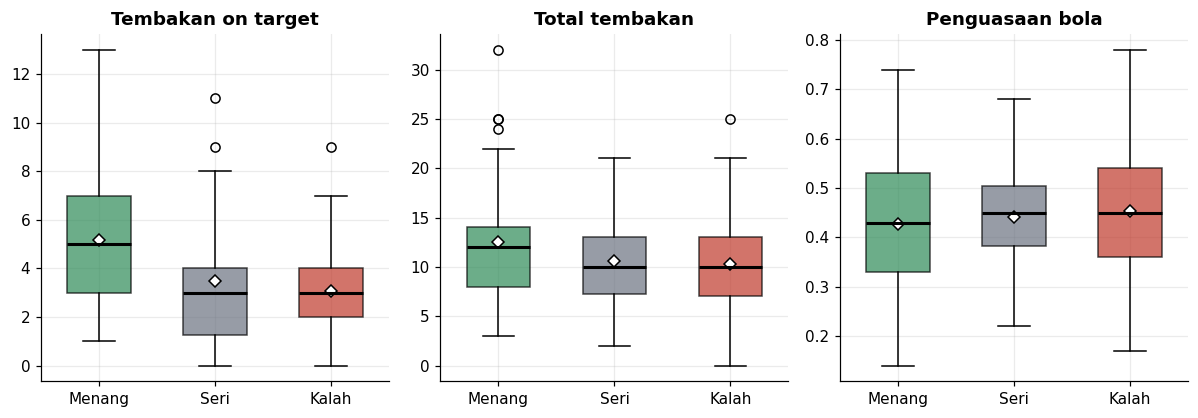

Menang vs Kalah, ont   Mann-Whitney p = 0.0001
Menang vs Kalah, att   Mann-Whitney p = 0.0852
Menang vs Kalah, poss  Mann-Whitney p = 0.2109
Kruskal-Wallis possession antar hasil p = 0.437
Win rate, on target >= 5 : 0.6 | < 5 : 0.28
Win rate, possession > 50%: 0.35 | <= 50%: 0.4


In [10]:
order = ['Menang', 'Seri', 'Kalah']
display(L.groupby('hasil')[['ont', 'att', 'poss', 'pacc', 'fouls', 'yc']].mean().loc[order].round(2))

fig, axs = plt.subplots(1, 3, figsize=(11, 3.9))
for ax, (c, t) in zip(axs, [('ont', 'Tembakan on target'), ('att', 'Total tembakan'), ('poss', 'Penguasaan bola')]):
    data = [L.loc[L.hasil == k, c] for k in order]
    bp = ax.boxplot(data, patch_artist=True, tick_labels=order, widths=.55, medianprops=dict(color='k', lw=2))
    for p_, cc in zip(bp['boxes'], [GR, G, R]): p_.set_facecolor(cc); p_.set_alpha(.7)
    ax.plot([1, 2, 3], [d.mean() for d in data], 'D', color='white', mec='k'); ax.set_title(t)
plt.tight_layout(); plt.show()

w, l = L[L.res == 1], L[L.res == -1]
for c in ['ont', 'att', 'poss']:
    print(f'Menang vs Kalah, {c:5s} Mann-Whitney p = {stats.mannwhitneyu(w[c], l[c])[1]:.4f}')
print('Kruskal-Wallis possession antar hasil p =', round(stats.kruskal(*[g['poss'] for _, g in L.groupby('res')])[1], 3))
print('Win rate, on target >= 5 :', round(L[L.ont >= 5].res.eq(1).mean(), 2), '| < 5 :', round(L[L.ont < 5].res.eq(1).mean(), 2))
print('Win rate, possession > 50%:', round(L[L.poss > .5].res.eq(1).mean(), 2), '| <= 50%:', round(L[L.poss <= .5].res.eq(1).mean(), 2))

B3. Fase grup vs fase gugur, dan pelanggaran vs kartu kuning

Gol/laga  Grup = 2.50 (n=48) | Gugur = 3.25 (n=16) | Mann-Whitney p = 0.080
Kartu/laga Grup = 3.50 | Gugur = 3.62 | p = 0.490


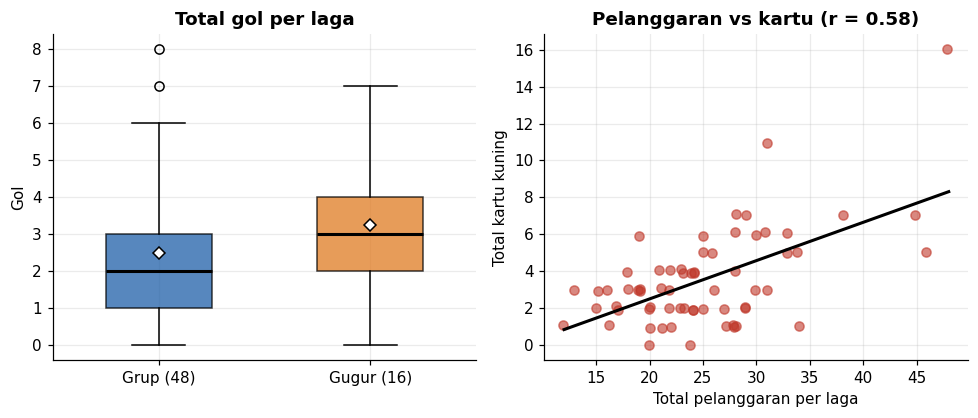

In [11]:
g, k = df.loc[df.stage == 'Grup', 'goals'], df.loc[df.stage == 'Gugur', 'goals']
print(f'Gol/laga  Grup = {g.mean():.2f} (n={len(g)}) | Gugur = {k.mean():.2f} (n={len(k)}) | Mann-Whitney p = {stats.mannwhitneyu(g, k)[1]:.3f}')
c1, c2 = df.loc[df.stage == 'Grup', 'cards'], df.loc[df.stage == 'Gugur', 'cards']
print(f'Kartu/laga Grup = {c1.mean():.2f} | Gugur = {c2.mean():.2f} | p = {stats.mannwhitneyu(c1, c2)[1]:.3f}')

fig, axs = plt.subplots(1, 2, figsize=(9, 3.9)); rng = np.random.RandomState(2)
bp = axs[0].boxplot([g, k], patch_artist=True, tick_labels=[f'Grup ({len(g)})', f'Gugur ({len(k)})'], widths=.5, medianprops=dict(color='k', lw=2))
for p_, cc in zip(bp['boxes'], [B, O]): p_.set_facecolor(cc); p_.set_alpha(.75)
axs[0].plot([1, 2], [g.mean(), k.mean()], 'D', color='white', mec='k'); axs[0].set(title='Total gol per laga', ylabel='Gol')
axs[1].scatter(df.fouls_total + rng.uniform(-.2, .2, len(df)), df.cards + rng.uniform(-.12, .12, len(df)), color=R, alpha=.6)
m, c0, r, p, _ = stats.linregress(df.fouls_total, df.cards); xs = np.linspace(df.fouls_total.min(), df.fouls_total.max(), 20)
axs[1].plot(xs, m * xs + c0, 'k', lw=2); axs[1].set(xlabel='Total pelanggaran per laga', ylabel='Total kartu kuning', title=f'Pelanggaran vs kartu (r = {r:.2f})')
plt.tight_layout(); plt.show()

B4. Matriks korelasi

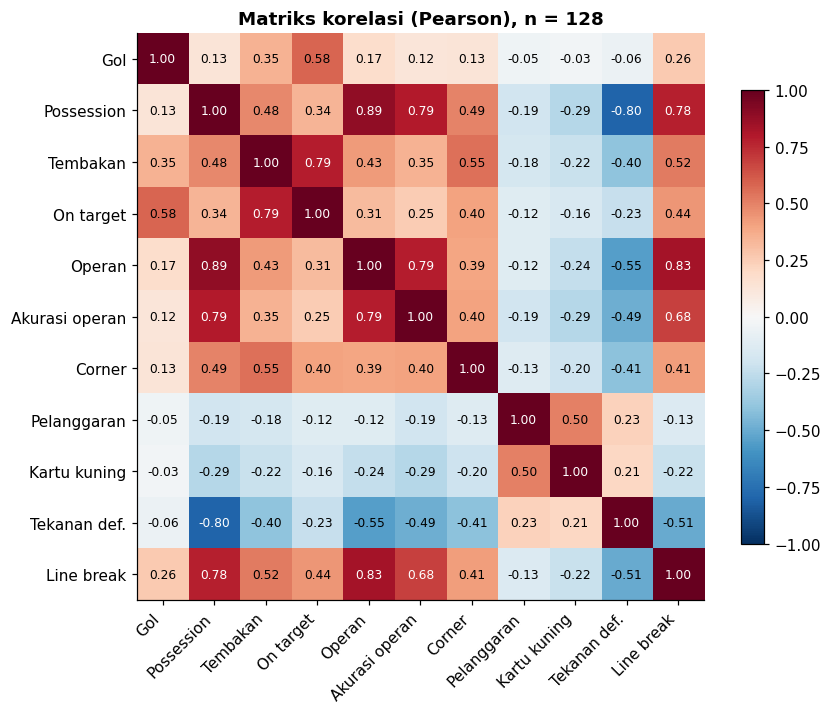

In [12]:
names = {'gf': 'Gol', 'poss': 'Possession', 'att': 'Tembakan', 'ont': 'On target', 'passes': 'Operan', 'pacc': 'Akurasi operan',
         'corners': 'Corner', 'fouls': 'Pelanggaran', 'yc': 'Kartu kuning', 'press': 'Tekanan def.', 'lb': 'Line break'}
Cm = L[list(names)].corr().rename(index=names, columns=names)
fig, ax = plt.subplots(figsize=(8.2, 6.6)); im = ax.imshow(Cm, cmap='RdBu_r', vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(Cm)), Cm.columns, rotation=45, ha='right'); ax.set_yticks(range(len(Cm)), Cm.index)
for i in range(len(Cm)):
    for j in range(len(Cm)):
        ax.text(j, i, f'{Cm.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8, color='white' if abs(Cm.iloc[i, j]) > .6 else 'black')
plt.colorbar(im, shrink=.8); ax.set_title('Matriks korelasi (Pearson), n = 128'); plt.tight_layout(); plt.show()